C:\Users\SANGLAP ROY\AppData\Local\Temp\ipykernel_5632\282861715.py:24: DtypeWarning: Columns (10: CONF_STATUS) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(RAW_FILE)


[SUCCESS] Coverage figure generated at: C:\Users\SANGLAP ROY\OneDrive\Desktop\AVIATION\reports\figures\coverage_verification_map.png


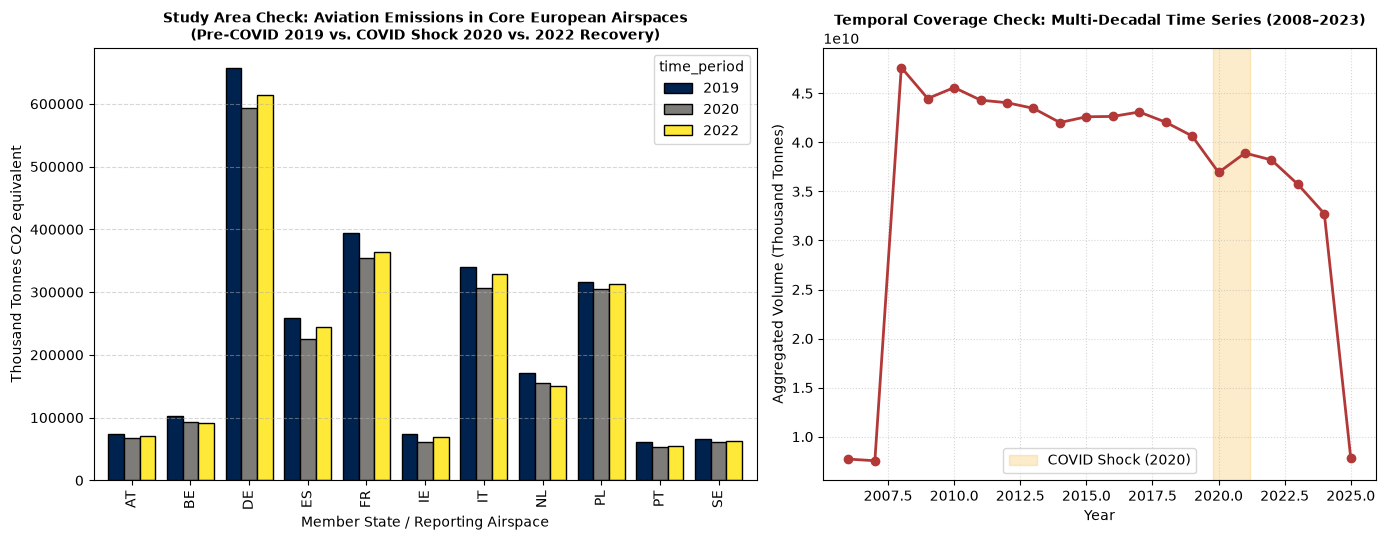

In [1]:
#!/usr/bin/env python3
"""
Assignment A2: Quick Map & Coverage Verification
File: scripts/plot_quick_map.py
Output: reports/figures/coverage_verification_map.png
"""

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

RAW_FILE = Path("C:/Users/SANGLAP ROY/OneDrive/Desktop/AVIATION/data/raw_data/eurostat_aviation_ghg_emissions.csv")
OUT_DIR = Path("C:/Users/SANGLAP ROY/OneDrive/Desktop/AVIATION/reports/figures")
#OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_FILE = OUT_DIR / "coverage_verification_map.png"


def plot_coverage():
    if not RAW_FILE.exists():
        print(f"[ERROR] {RAW_FILE} not found. Run scripts/01_get_data.py first.")
        sys.exit(1)

    df = pd.read_csv(RAW_FILE)
    df.columns = [c.lower() for c in df.columns]

    time_col = "time_period" if "time_period" in df.columns else "time"
    val_col = "obs_value" if "obs_value" in df.columns else "value"
    geo_col = "geo" if "geo" in df.columns else "unit"

    df_clean = df[[geo_col, time_col, val_col]].dropna()
    df_clean[time_col] = pd.to_numeric(df_clean[time_col], errors="coerce")
    df_clean[val_col] = pd.to_numeric(df_clean[val_col], errors="coerce")
    df_clean = df_clean.dropna()

    # Core European flight corridor entities
    corridors = [
        "DE",
        "FR",
        "ES",
        "IT",
        "NL",
        "PT",
        "AT",
        "BE",
        "PL",
        "SE",
        "IE",
    ]
    df_corr = df_clean[df_clean[geo_col].isin(corridors)]
    pivot = df_corr.pivot_table(
        index=geo_col, columns=time_col, values=val_col, aggfunc="mean"
    )

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]}
    )

    # 1. Spatial Coverage Check across European Core Airspaces
    pivot[[2019, 2020, 2022]].plot(
        kind="bar", ax=ax1, colormap="cividis", edgecolor="black", width=0.8
    )
    ax1.set_title(
        "Study Area Check: Aviation Emissions in Core European Airspaces\n(Pre-COVID 2019 vs. COVID Shock 2020 vs. 2022 Recovery)",
        fontsize=10,
        fontweight="bold",
    )
    ax1.set_ylabel("Thousand Tonnes CO2 equivalent")
    ax1.set_xlabel("Member State / Reporting Airspace")
    ax1.grid(axis="y", linestyle="--", alpha=0.5)

    # 2. Temporal Coverage Check across All Years
    trend = (
        df_clean[df_clean[geo_col].isin(["EU27_2020", "DE", "FR"])]
        .groupby(time_col)[val_col]
        .sum()
    )
    ax2.plot(trend.index, trend.values, marker="o", color="#b33939", linewidth=2)
    ax2.axvspan(
        2019.8, 2021.2, color="#f7b731", alpha=0.25, label="COVID Shock (2020)"
    )
    ax2.set_title(
        "Temporal Coverage Check: Multi-Decadal Time Series (2008–2023)",
        fontsize=10,
        fontweight="bold",
    )
    ax2.set_xlabel("Year")
    ax2.set_ylabel("Aggregated Volume (Thousand Tonnes)")
    ax2.grid(True, linestyle=":", alpha=0.5)
    ax2.legend()

    plt.tight_layout()
    plt.savefig(OUT_FILE, dpi=300)
    print(f"[SUCCESS] Coverage figure generated at: {OUT_FILE}")


if __name__ == "__main__":
    plot_coverage()